# 01. 서울 아파트 거래가격과 거래량의 변화

**연구 질문 1**: 서울 아파트의 거래가격과 거래량은 어떻게 변화했을까?

- 사용 데이터: `data/서울_아파트_매매_실거래가_2017-2026_통합.xlsx` (2017년 10월 ~ 2026년 10월 계약분)
- 이 노트북은 가격·거래량의 **단순 변화**를 살펴봅니다. 변화의 원인은 여기서 판단하지 않습니다.

## 1. 데이터 불러오기 및 정제

정제 기준
1. 계약이 해제된 거래(`해제사유발생일`에 날짜가 있는 행)는 실제로 이루어지지 않은 거래이므로 삭제합니다.
2. `NO`(일련번호)만 다르고 나머지 값이 모두 같은 행은 중복 거래로 보고 하나만 남깁니다.
3. `거래금액(만원)`은 `86,000`처럼 쉼표가 들어간 문자열이므로 숫자로 바꿉니다.
4. 분석에 쓸 `구`, `계약일자`, `연도` 열을 새로 만들고, 필요한 열만 남깁니다.

In [1]:
# 실거래가 엑셀 파일을 불러와 해제 거래·중복 거래를 지우고 분석용 열을 만든다
import pandas as pd

# 1) 데이터 불러오기 (약 55만 행이라 불러오는 데 30~40초 정도 걸린다)
df = pd.read_excel('../data/서울_아파트_매매_실거래가_2017-2026_통합.xlsx')
print('원본 크기:', df.shape)

# 2) 결측치 확인
print('결측치 개수 합계:', df.isnull().sum().sum())

# 3) 계약이 해제된 거래 삭제 ('-'이면 해제되지 않은 거래)
print('해제된 거래 수:', (df['해제사유발생일'] != '-').sum())
df = df[df['해제사유발생일'] == '-']

# 4) NO만 다른 중복 거래 삭제
before = len(df)
df = df.drop_duplicates(subset=df.columns.drop('NO'))
print('삭제한 중복 거래 수:', before - len(df))

# 5) 거래금액의 쉼표를 지우고 정수로 바꾸기
df['거래금액(만원)'] = df['거래금액(만원)'].str.replace(',', '').astype(int)

# 6) 시군구에서 구 이름만 꺼내기 (예: '서울특별시 중구 신당동' -> '중구')
df['구'] = df['시군구'].str.split().str[1]

# 7) 계약년월 + 계약일로 날짜 열과 연도 열 만들기
df['계약일자'] = pd.to_datetime(df['계약년월'].astype(str) + df['계약일'].astype(str).str.zfill(2), format='%Y%m%d')
df['연도'] = df['계약일자'].dt.year

# 8) 분석에 필요한 열만 남기고 인덱스 다시 매기기
df = df[['구', '시군구', '단지명', '전용면적(㎡)', '층', '건축년도', '계약년월', '계약일자', '연도', '거래금액(만원)']]
df = df.reset_index(drop=True)

print('정제 후 크기:', df.shape)
print('구 개수:', df['구'].nunique())
print('계약 기간:', df['계약일자'].min().date(), '~', df['계약일자'].max().date())
df.head()

원본 크기: (547735, 21)
결측치 개수 합계: 0
해제된 거래 수: 17606


삭제한 중복 거래 수: 4180


정제 후 크기: (525949, 10)
구 개수: 25
계약 기간: 2017-10-28 ~ 2026-10-26


,구,시군구,단지명,전용면적(㎡),층,건축년도,계약년월,계약일자,연도,거래금액(만원)
0,중구,서울특별시 중구 신당동,신당푸르지오,84.76,13,2005,201810,2018-10-27,2018,86000
1,성북구,서울특별시 성북구 돈암동,한신,68.13,5,1998,201810,2018-10-27,2018,45900
2,용산구,서울특별시 용산구 효창동,효삼골드빌,77.15,1,2004,201810,2018-10-27,2018,44000
3,광진구,서울특별시 광진구 광장동,워커힐푸르지오,65.66,11,1987,201810,2018-10-27,2018,68000
4,광진구,서울특별시 광진구 광장동,광장자이,158.26,5,2008,201810,2018-10-27,2018,154000


## 2. 연도별 거래량과 거래가격

- 연도마다 거래 건수와 거래금액 **중앙값**을 구합니다. 일부 초고가 거래가 평균을 끌어올릴 수 있어서 평균 대신 중앙값을 씁니다.
- 연도마다 데이터가 있는 개월 수(`개월수`)도 같이 셉니다. 2017년은 10월 말부터, 2026년은 10월까지만 있어서 다른 연도와 거래 건수를 그대로 비교하면 안 됩니다.

In [2]:
# 연도별 거래 건수, 거래금액 중앙값, 데이터가 있는 개월 수를 표로 만든다
yearly = df.groupby('연도').agg(
    거래건수=('거래금액(만원)', 'count'),
    거래금액_중앙값=('거래금액(만원)', 'median'),
    개월수=('계약년월', 'nunique')
)

# 12개월이 다 있지 않은 연도는 표시해 두기
yearly['전체기간여부'] = yearly['개월수'] == 12

yearly

,거래건수,거래금액_중앙값,개월수,전체기간여부
연도,,,,
2017,17759,58500.0,3,False
2018,81293,53000.0,12,True
2019,74606,67000.0,12,True
2020,80462,71000.0,12,True
2021,41639,84700.0,12,True
2022,11568,76000.0,12,True
2023,33642,88000.0,12,True
2024,54857,96500.0,12,True
2025,76761,105000.0,12,True


## 3. 연도별 가격 중앙값이 달라진 이유 확인하기

2017년 중앙값이 2018년보다 높고, 2026년 중앙값이 2025년보다 낮게 나왔습니다. 가격 자체가 내린 것인지, **그해에 거래된 아파트의 구성이 달라서**인지 확인합니다.

- `면적_중앙값`: 작은 아파트가 많이 거래된 해는 거래금액 중앙값이 낮아질 수 있습니다.
- `제곱미터당가격_중앙값`: 거래금액을 전용면적으로 나눠 면적 차이의 영향을 줄인 가격입니다.
- `강남3구_비중`: 비싼 지역(강남구·서초구·송파구)의 거래가 많았던 해는 중앙값이 높아질 수 있습니다.

In [3]:
# 연도별 면적 중앙값, ㎡당 가격 중앙값, 강남3구 거래 비중을 구해 거래 구성의 차이를 확인한다
# 1) 거래금액을 전용면적으로 나눠 ㎡당 가격 열 만들기
df['㎡당가격(만원)'] = df['거래금액(만원)'] / df['전용면적(㎡)']

# 2) 강남구·서초구·송파구 거래인지 표시하기 (True/False)
df['강남3구'] = df['구'].isin(['강남구', '서초구', '송파구'])

# 3) 연도별로 묶어서 구성 지표 구하기 (True/False의 평균 = 비중)
mix = df.groupby('연도').agg(
    거래금액_중앙값=('거래금액(만원)', 'median'),
    면적_중앙값=('전용면적(㎡)', 'median'),
    제곱미터당가격_중앙값=('㎡당가격(만원)', 'median'),
    강남3구_비중=('강남3구', 'mean')
)

mix.round(3)

,거래금액_중앙값,면적_중앙값,제곱미터당가격_중앙값,강남3구_비중
연도,,,,
2017,58500.0,84.640,750.796,0.231
2018,53000.0,84.390,702.063,0.138
2019,67000.0,83.580,903.490,0.182
2020,71000.0,79.870,981.093,0.137
2021,84700.0,70.690,1217.497,0.150
2022,76000.0,59.980,1176.471,0.176
2023,88000.0,75.015,1225.914,0.189
2024,96500.0,82.340,1323.997,0.197
2025,105000.0,82.350,1412.928,0.158


## 4. 같은 구 안에서도 ㎡당 가격이 내렸을까?

구 구성의 영향을 빼기 위해 **같은 구끼리** ㎡당 가격 중앙값을 비교합니다. 계절에 따른 차이도 줄이기 위해 **같은 달끼리만** 비교합니다.

- 2017년 vs 2018년: 두 해 모두 데이터가 온전한 **11~12월**만 비교 (2017년 10월은 28일부터만 있음)
- 2025년 vs 2026년: 2026년 데이터가 있는 **1~10월**만 비교

25개 구 가운데 ㎡당 가격이 내린 구가 대부분이면 실제 가격 하락에 가깝고, 일부뿐이면 거래 구성의 영향이 컸다고 볼 수 있습니다.

In [4]:
# 같은 달끼리 구별 ㎡당 가격 중앙값을 비교해 2017→2018, 2025→2026 변화율을 구한다
# 1) 계약 월 열 만들기
df['월'] = df['계약일자'].dt.month

# 2) 2017년 vs 2018년 (11~12월만)
y2017 = df[(df['연도'] == 2017) & (df['월'] >= 11)].groupby('구')['㎡당가격(만원)'].median()
y2018 = df[(df['연도'] == 2018) & (df['월'] >= 11)].groupby('구')['㎡당가격(만원)'].median()

# 3) 2025년 vs 2026년 (1~10월만)
y2025 = df[(df['연도'] == 2025) & (df['월'] <= 10)].groupby('구')['㎡당가격(만원)'].median()
y2026 = df[(df['연도'] == 2026) & (df['월'] <= 10)].groupby('구')['㎡당가격(만원)'].median()

# 4) 구별 비교표 만들기 (변화율 단위: %)
gu_compare = pd.DataFrame({
    '2017_11~12월': y2017,
    '2018_11~12월': y2018,
    '변화율_17→18': (y2018 - y2017) / y2017 * 100,
    '2025_1~10월': y2025,
    '2026_1~10월': y2026,
    '변화율_25→26': (y2026 - y2025) / y2025 * 100
})

# 5) ㎡당 가격이 내린 구의 수 세기
print('2017→2018 ㎡당 가격이 내린 구:', (gu_compare['변화율_17→18'] < 0).sum(), '/ 25')
print('2025→2026 ㎡당 가격이 내린 구:', (gu_compare['변화율_25→26'] < 0).sum(), '/ 25')

gu_compare.round(1).sort_values('변화율_25→26')

2017→2018 ㎡당 가격이 내린 구: 4 / 25
2025→2026 ㎡당 가격이 내린 구: 6 / 25


,2017_11~12월,2018_11~12월,변화율_17→18,2025_1~10월,2026_1~10월,변화율_25→26
구,,,,,,
양천구,851.6,618.8,-27.3,1505.2,1376.9,-8.5
종로구,754.2,744.3,-1.3,1396.2,1306.0,-6.5
서대문구,691.7,706.8,2.2,1407.1,1331.5,-5.4
마포구,863.9,935.7,8.3,1892.7,1841.7,-2.7
은평구,608.8,593.1,-2.6,1167.6,1137.4,-2.6
도봉구,481.1,494.5,2.8,788.4,782.4,-0.8
서초구,1209.7,1219.6,0.8,2587.6,2636.8,1.9
구로구,563.2,608.1,8.0,981.4,1002.4,2.1
강북구,517.8,585.7,13.1,910.2,931.4,2.3


## 5. 월별 거래량과 ㎡당 가격 한눈에 보기

- 위: 월별 거래 건수, 아래: 월별 ㎡당 가격 중앙값
- 거래금액 중앙값은 그달 거래된 면적과 지역 구성에 따라 크게 흔들리므로(3·4절), 가격은 **㎡당 가격**으로 그립니다.
- 2017년 10월은 28일부터만 있어서 뺍니다. 2026년 9~10월은 아직 신고가 덜 들어왔을 수 있어 회색으로 표시합니다.

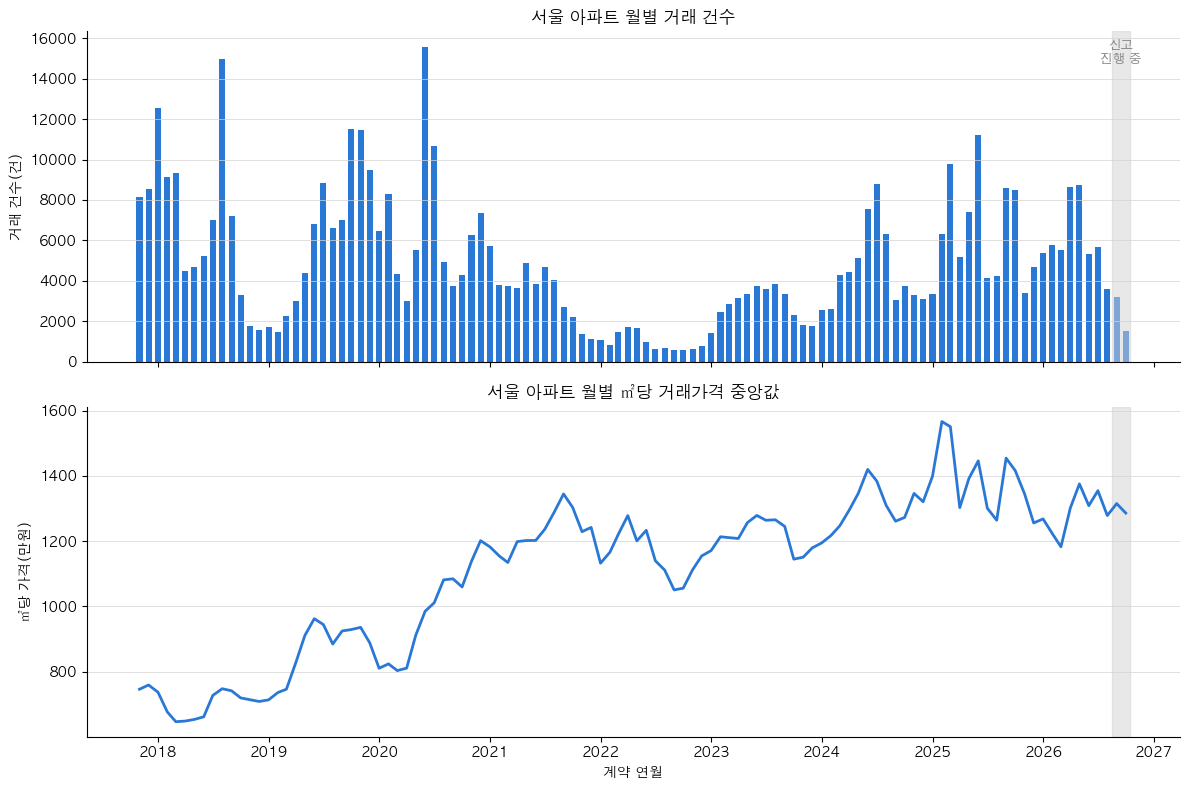

In [5]:
# 월별 거래 건수와 ㎡당 가격 중앙값을 위아래 두 그래프로 그리고 PNG로 저장한다
import matplotlib.pyplot as plt

# 1) 한글 폰트 설정 (맥 기본 폰트), 마이너스 기호 깨짐 방지
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

# 2) 월별로 거래 건수와 ㎡당 가격 중앙값 구하기 (2017년 10월은 제외)
monthly = df[df['계약년월'] != 201710].groupby('계약년월').agg(
    거래건수=('거래금액(만원)', 'count'),
    제곱미터당가격_중앙값=('㎡당가격(만원)', 'median')
)

# 3) 계약년월(예: 201711)을 날짜로 바꿔 x축으로 쓰기
monthly.index = pd.to_datetime(monthly.index.astype(str), format='%Y%m')

# 4) 위아래 두 그래프 만들기 (x축 공유)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# 5) 위: 월별 거래 건수 막대그래프
ax1.bar(monthly.index, monthly['거래건수'], width=20, color='#2a78d6')
ax1.set_title('서울 아파트 월별 거래 건수')
ax1.set_ylabel('거래 건수(건)')

# 6) 아래: 월별 ㎡당 가격 중앙값 선그래프
ax2.plot(monthly.index, monthly['제곱미터당가격_중앙값'], color='#2a78d6', linewidth=2)
ax2.set_title('서울 아파트 월별 ㎡당 거래가격 중앙값')
ax2.set_ylabel('㎡당 가격(만원)')
ax2.set_xlabel('계약 연월')

# 7) 두 그래프 공통: 신고가 덜 들어왔을 수 있는 2026년 9~10월 회색 표시, 옅은 격자
for ax in [ax1, ax2]:
    ax.axvspan(pd.Timestamp('2026-08-16'), pd.Timestamp('2026-10-16'), color='lightgray', alpha=0.5)
    ax.grid(axis='y', color='lightgray', linewidth=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
ax1.text(pd.Timestamp('2026-09-15'), monthly['거래건수'].max() * 0.95, '신고\n진행 중', ha='center', fontsize=9, color='gray')

# 8) 그래프 저장 후 화면에 보여주기
plt.tight_layout()
plt.savefig('../outputs/01_월별_거래량_가격.png', dpi=150)
plt.show()

## 6. 결론

**연구 질문 1: 서울 아파트의 거래가격과 거래량은 어떻게 변화했을까?**

- **거래량**: 2018~2020년에는 한 달 수천~1만5천 건 사이에서 크게 오르내렸고, 2022년에는 한 달 500~1,000건 수준까지 줄었습니다. 2024년부터 다시 늘어 2025년에는 연 7만 건대를 회복했습니다.
- **가격**: ㎡당 가격 중앙값은 2018년 약 700만 원에서 2025년 약 1,400만 원으로 약 2배가 되었습니다. 2022년에는 일시적으로 내렸습니다.
- **주의할 점**: 서울 전체 거래금액 중앙값만 보면 2018년과 2026년에 가격이 내린 것처럼 보입니다. 하지만 같은 구·같은 달끼리 비교하면 25개 구 중 19~21개 구의 ㎡당 가격이 올랐습니다. 전체 중앙값이 내린 것은 그해 비싼 구(강남3구)나 큰 면적의 거래 비중이 줄어든, **거래 구성 차이의 영향이 커 보입니다**.

이 노트북은 가격과 거래량의 **단순 변화**만 확인했습니다. 가격이 왜 변했는지(금리, 정부 대책 등과의 관계)는 이후 연구 질문에서 다룹니다.